# AskCampus: An NLP-Based Student Information Chatbot for University Students

**Section:** BSCS231A

**Domain:** Student Services (University Administrative AI Support)



## 0. Setup — Install & Import Libraries

In [1]:
!pip install -q nltk scikit-learn pandas numpy matplotlib seaborn

import re
import string
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## Phase 1: Dataset Loading

The dataset used for training is the provided `intents.json` file directly — no hand-typed dictionary. Each entry in the file has an `intent` label, a list of user-phrased `text` patterns, and a list of canned `responses`. We parse this nested structure below into a flat (query, intent) table for training, and keep the `responses` around to power the chatbot's replies later.


In [2]:
import json
import os

# Works whether the notebook is run from /notebooks in the GitHub repo
# (data lives one level up, in /data), from Colab (/content), or from the
# same folder as intents.json.
_candidate_paths = [
    'intents.json',
    '../data/intents.json',
    '/content/intents.json',
]
INTENTS_PATH = next((p for p in _candidate_paths if os.path.exists(p)), _candidate_paths[0])

with open(INTENTS_PATH, 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

rows = []
response_bank = {}
skipped_entries = []

for entry in raw_data['intents']:
    intent_name = entry.get('intent')
    patterns = entry.get('text')
    responses = entry.get('responses', [])

    # Guard against malformed entries in the source file (e.g. a missing
    # 'intent' or empty 'text' list) instead of letting them crash training.
    if not intent_name or not patterns:
        skipped_entries.append(entry)
        continue

    response_bank[intent_name] = responses
    for pattern in patterns:
        rows.append({"query": pattern, "intent": intent_name})

df = pd.DataFrame(rows)

print(f"Total intents loaded: {df['intent'].nunique()}")
print(f"Total sample queries: {len(df)}")
if skipped_entries:
    print(f"Skipped {len(skipped_entries)} malformed entr"
          f"{'y' if len(skipped_entries) == 1 else 'ies'} missing 'intent' or 'text'.")

df['intent'].value_counts()


Total intents loaded: 38
Total sample queries: 409


intent
course              19
admission           18
hours               17
fees                17
creator             16
document_request    16
number              15
dormitory           15
location            14
library             14
office_location     14
name                13
document            13
salutation          13
goodbye             12
vacation            12
event               11
canteen             11
sem                 11
scholarship         11
greeting            10
computerhod         10
ragging             10
placement            9
college intake       9
uniform              9
swear                9
floors               7
syllabus             7
menu                 7
principal            7
sports               7
committee            6
task                 6
facilities           5
infrastructure       3
random               3
hod                  3
Name: count, dtype: int64

### Fix note: resolving the intents.json mismatch

An earlier draft of this notebook defined its own hand-typed `intents` dictionary (10 university-specific classes) and trained the model on *that*, while a separate cell loaded `intents.json` into an unused DataFrame that was printed once and never touched again — the two datasets never actually met.

This version removes the hard-coded dictionary entirely. `df` above is built directly from `intents.json`, and `response_bank` (also built above) reuses each intent's own `responses` list from the file instead of a second, hand-written response dictionary later in the notebook. There is exactly one source of truth for both training data and replies now.


In [3]:
df.sample(10, random_state=RANDOM_STATE)

,query,intent
172,size of campus,floors
137,is there a dorm,dormitory
126,college address,location
94,what programs do you have,course
72,college number,number
33,who created you,creator
379,how do i get my transcript of records,document_request
223,What is average package,placement
341,give sports details,sports
227,placement,placement


## Phase 2: NLP Pipeline & Model Training



In [4]:
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Lowercase, remove punctuation, tokenize, and lemmatize a student query."""
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    lemmas = [lemmatizer.lemmatize(tok) for tok in tokens]
    return " ".join(lemmas)

df['clean_query'] = df['query'].apply(preprocess_text)
df[['query', 'clean_query']].head(10)


,query,clean_query
0,Hi,hi
1,How are you?,how are you
2,Is anyone there?,is anyone there
3,Hello,hello
4,Good day,good day
5,What's up,whats up
6,how are ya,how are ya
7,heyy,heyy
8,whatsup,whatsup
9,??? ??? ??,


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_query'], df['intent'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df['intent']
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")


Training samples: 327
Testing samples: 82


In [6]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Training matrix shape: {X_train_tfidf.shape}")


Vocabulary size: 720
Training matrix shape: (327, 720)


In [7]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)
nb_acc = accuracy_score(y_test, nb_preds)

# intents.json has some very small classes (as few as 3 patterns total), so a
# fixed cv=3 can fail once a class only has 1-2 examples in the training fold.
# Pick the largest safe fold count instead of hard-coding it.
min_class_count = y_train.value_counts().min()
safe_cv = max(2, min(3, min_class_count))

svc_base = LinearSVC(random_state=RANDOM_STATE, max_iter=10000)
svc_model = CalibratedClassifierCV(svc_base, cv=safe_cv)
svc_model.fit(X_train_tfidf, y_train)
svc_preds = svc_model.predict(X_test_tfidf)
svc_acc = accuracy_score(y_test, svc_preds)

print(f"Multinomial Naive Bayes accuracy: {nb_acc:.4f}")
print(f"LinearSVC (calibrated) accuracy:  {svc_acc:.4f}")

if svc_acc >= nb_acc:
    best_model, best_name, best_preds = svc_model, "LinearSVC", svc_preds
else:
    best_model, best_name, best_preds = nb_model, "Multinomial Naive Bayes", nb_preds

print(f"\nSelected model for chatbot deployment: {best_name}")


Multinomial Naive Bayes accuracy: 0.5976
LinearSVC (calibrated) accuracy:  0.7683

Selected model for chatbot deployment: LinearSVC


## Phase 3: Chatbot Integration & Logic




In [8]:
CONFIDENCE_THRESHOLD = 0.35

fallback_response = (
    "I'm sorry, I'm not confident I understood that correctly. "
    "Could you rephrase your question, or contact the relevant office directly?"
)

def predict_intent(query, model=None, vec=None, threshold=CONFIDENCE_THRESHOLD):
    """Classify a student query and return (intent, confidence), applying a fallback
    if the model's confidence is below the threshold.

    model/vec default to None and are looked up from the current globals at
    call time (not def time) -- this is deliberate: it means this function
    automatically uses whichever model is current, including the FINAL
    exported model once that cell runs later in the notebook, rather than
    being permanently frozen to the 80/20-split evaluation model.
    """
    if model is None:
        model = best_model
    if vec is None:
        vec = vectorizer
    clean = preprocess_text(query)
    features = vec.transform([clean])

    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(features)[0]
        top_idx = np.argmax(probs)
        confidence = probs[top_idx]
        intent = model.classes_[top_idx]
    else:
        intent = model.predict(features)[0]
        confidence = 1.0  # no probability available

    if confidence < threshold:
        return None, confidence
    return intent, confidence


def chatbot_response(query):
    intent, confidence = predict_intent(query)
    if intent is None:
        return fallback_response, confidence, None
    # response_bank comes straight from intents.json (built when we loaded the
    # data), so replies stay in sync with the dataset instead of a second,
    # hand-written template dictionary that can drift out of date.
    candidates = response_bank.get(intent) or [fallback_response]
    return random.choice(candidates), confidence, intent


In [9]:
# Quick sanity check on a few unseen phrasings
test_queries = [
    "how much are the tuition fees this semester",
    "where is the library located",
    "can I get a copy of my documents",
    "what time does the canteen open",  # likely low-confidence / out of scope
]

for q in test_queries:
    reply, conf, intent = chatbot_response(q)
    print(f"Query: {q}")
    print(f"  -> Predicted intent: {intent} (confidence: {conf:.2f})")
    print(f"  -> Response: {reply}\n")


Query: how much are the tuition fees this semester
  -> Predicted intent: fees (confidence: 0.67)
  -> Response: Sure -- are you enrolled in Computer Science, Information Technology, or Information System? I can give you the tuition and fee breakdown for that program.

Query: where is the library located
  -> Predicted intent: library (confidence: 0.47)
  -> Response: The library is on the 2nd floor, in the middle across the hallway. It's open 8am to 6pm.

Query: can I get a copy of my documents
  -> Predicted intent: document_request (confidence: 0.47)
  -> Response: You can request official documents -- Transcript of Records, Certificate of Enrollment, Good Moral Certificate, Diploma, or Honorable Dismissal -- through the Registrar's Office. Processing usually takes 3-5 working days. Bring a valid ID and your request slip when claiming.

Query: what time does the canteen open
  -> Predicted intent: None (confidence: 0.33)
  -> Response: I'm sorry, I'm not confident I understood that 

### Phase 3b: Dialogue manager (multi-turn context)

The classifier only sees **one message at a time**. On its own it can't tell that "computer science", typed right after "how much are the fees?", answers the bot's question, so it classifies it as the `course` intent again. The layer below adds conversation state around the model:

- **Course entity extraction:** aliases (`comsci`, `infotech`...) plus `difflib` fuzzy matching for typos ("compute4r science"). The 2-letter codes `cs`/`it`/`is` only count when they're the whole message, or when the message is already about fees, so "where **is** the library" isn't read as Information System.
- **Sticky fees context:** after a fees question, naming a program returns its fee breakdown until the topic changes.
- **Same-message handling:** "what are the fees for computer science" is answered directly.
- **Yes/no follow-up** after admission, scholarship, dormitory, placement and document answers.

**The ML model still makes every intent decision.** This layer only resolves follow-ups that a single-message classifier can't see. State lives in a `ConversationState` object per user, not in globals, so the web backend can serve several users at once.

The cell below writes this logic to **`askcampus_dialogue.py`**. Copy that file into `backend/` together with the `.joblib` files. `app.py` imports it, so the notebook demo and the web app run the **same code**.


In [ ]:
%%writefile askcampus_dialogue.py
"""
askcampus_dialogue.py -- AskCampus conversation logic, shared by the
notebook (run_cli_chatbot) and the Flask backend (app.py).

The ML model (TF-IDF + calibrated LinearSVC) makes every intent decision.
This module adds what a single-message classifier cannot see on its own:

  * Course entity extraction -- aliases, safe handling of the 2-letter codes
    "cs"/"it"/"is", and difflib fuzzy matching for typos.
  * Sticky fees context -- after a fees question, naming a program returns
    that program's fee breakdown until the topic clearly changes.
  * Same-message handling -- "what are the fees for computer science?"
  * A yes/no follow-up after admission/scholarship/dorm/placement/document.

All conversation state lives in a ConversationState object, so every user
gets their own conversation (no module-level globals).
"""

import re
import random
import string
import difflib
from dataclasses import dataclass, field
import time

import numpy as np
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

_lemmatizer = WordNetLemmatizer()

CONFIDENCE_THRESHOLD = 0.35
FALLBACK_RESPONSE = (
    "I'm sorry, I'm not confident I understood that correctly. "
    "Could you rephrase your question, or contact the relevant office directly?"
)


# ---------------------------------------------------------------------------
# Preprocessing -- must stay identical to the notebook's training pipeline
# ---------------------------------------------------------------------------
def preprocess_text(text):
    """Lowercase, remove punctuation, tokenize, and lemmatize."""
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    return " ".join(_lemmatizer.lemmatize(tok) for tok in tokens)


# ---------------------------------------------------------------------------
# Course knowledge (generic sample figures for the demo)
# ---------------------------------------------------------------------------
COURSE_FEES = {
    "computer science": {"tuition_per_unit": 1350, "laboratory": 4000, "misc": 3000, "classroom": 1000, "id_fee": 150},
    "information technology": {"tuition_per_unit": 1300, "laboratory": 3800, "misc": 3000, "classroom": 1000, "id_fee": 150},
    "information system": {"tuition_per_unit": 1250, "laboratory": 3200, "misc": 3000, "classroom": 1000, "id_fee": 150},
}
COURSE_ALIASES = {
    "computer science": "computer science", "computerscience": "computer science",
    "compsci": "computer science", "comsci": "computer science", "cs": "computer science",
    "information technology": "information technology", "infotech": "information technology",
    "info tech": "information technology", "it": "information technology",
    "information system": "information system", "information systems": "information system",
    "info system": "information system", "infosystem": "information system", "is": "information system",
}
STANDARD_LOAD_UNITS = 21

# Keywords used only for typo-tolerant fuzzy matching (not exact matching).
COURSE_KEYWORDS = {
    "computer science": ["computer", "science"],
    "information technology": ["information", "technology"],
    "information system": ["information", "system"],
}

FOLLOWUP_INTENTS = {"admission", "scholarship", "dormitory", "placement", "document", "document_request"}
YES_WORDS = {"yes", "yeah", "yep", "yup", "sure", "ok", "okay", "opo", "oo"}
NO_SINGLE_WORDS = {"no", "nope", "nah", "wala", "hindi"}
NO_PHRASES = {"no thanks", "im good", "i'm good"}


def fuzzy_match_course(message):
    """Catch minor typos (e.g. 'compute4r science') by comparing each word
    against known course keywords by similarity instead of exact match."""
    words = re.sub(r"[^a-z0-9\s]", " ", message.lower()).split()
    best_course, best_score = None, 0.0
    for course, keywords in COURSE_KEYWORDS.items():
        hits = sum(
            1 for kw in keywords
            if any(difflib.SequenceMatcher(None, w, kw).ratio() >= 0.8 for w in words)
        )
        score = hits / len(keywords)
        if score > best_score:
            best_score, best_course = score, course
    return best_course if best_score >= 0.5 else None


def match_course(message, relaxed=False):
    """Return the canonical course name mentioned in `message`, or None.

    Bare 2-letter codes ("cs", "it", "is") collide with English words, so:
    relaxed=True  (message already classified as fees) -> trust them anywhere,
    relaxed=False -> only when the code is the ENTIRE message ("IT").
    """
    text = message.lower().strip()
    words = text.split()

    for alias in sorted(COURSE_ALIASES, key=len, reverse=True):
        if len(alias) > 2 and re.search(rf"\b{re.escape(alias)}\b", text):
            return COURSE_ALIASES[alias]

    if relaxed:
        for code in ("cs", "it", "is"):
            if re.search(rf"\b{re.escape(code)}\b", text):
                return COURSE_ALIASES[code]
    else:
        if len(words) == 1 and words[0].strip(string.punctuation) in ("cs", "it", "is"):
            return COURSE_ALIASES[words[0].strip(string.punctuation)]
        # Code at the END of a message, right after a cue word: "what about IT",
        # "how about cs?", "I'm taking IS". "is scholarship available" does not match.
        m = re.search(r"\b(?:about|for|in|of|taking|under|sa)\s+(cs|it|is)\s*[?.!]*$", text)
        if m:
            return COURSE_ALIASES[m.group(1)]

    return fuzzy_match_course(message)


def build_fee_breakdown(course):
    fees = COURSE_FEES[course]
    tuition_total = fees["tuition_per_unit"] * STANDARD_LOAD_UNITS
    grand_total = tuition_total + fees["laboratory"] + fees["misc"] + fees["classroom"] + fees["id_fee"]
    return (
        f"Here's a generic fee breakdown for {course.title()} (based on a standard {STANDARD_LOAD_UNITS}-unit load):\n"
        f"- Tuition: PHP {fees['tuition_per_unit']:,}/unit x {STANDARD_LOAD_UNITS} units = PHP {tuition_total:,}\n"
        f"- Laboratory Fee: PHP {fees['laboratory']:,}\n"
        f"- Miscellaneous Fee: PHP {fees['misc']:,}\n"
        f"- Classroom/Facilities Fee: PHP {fees['classroom']:,}\n"
        f"- ID Fee: PHP {fees['id_fee']:,}\n"
        f"Estimated Total: PHP {grand_total:,}\n\n"
        f"Want the breakdown for another program too? Just say Computer Science, IT, or IS.\n"
        f"(These are generic sample figures for this demo -- actual fees are published each semester by the Finance Office.)"
    )


def is_yes(text):
    words = re.findall(r"[a-z']+", text.lower())
    return len(words) <= 3 and any(w in YES_WORDS for w in words)


def is_no(text):
    t = text.lower().strip()
    if t in NO_PHRASES:
        return True
    words = re.findall(r"[a-z']+", t)
    return len(words) <= 3 and any(w in NO_SINGLE_WORDS for w in words)


# ---------------------------------------------------------------------------
# Conversation state + the bot
# ---------------------------------------------------------------------------
@dataclass
class ConversationState:
    """Everything the bot remembers about ONE user's conversation."""
    last_topic: str = None
    awaiting_followup: bool = False
    last_seen: float = field(default_factory=time.time)


class AskCampusBot:
    """Wraps the trained model + vectorizer + replies. Stateless itself:
    pass a ConversationState into respond() for each user."""

    def __init__(self, model, vectorizer, response_bank, threshold=CONFIDENCE_THRESHOLD):
        self.model = model
        self.vectorizer = vectorizer
        self.response_bank = response_bank
        self.threshold = threshold

    def classify(self, message):
        """Run the ML pipeline: preprocess -> TF-IDF -> calibrated LinearSVC."""
        features = self.vectorizer.transform([preprocess_text(message)])
        probs = self.model.predict_proba(features)[0]
        top_idx = int(np.argmax(probs))
        return self.model.classes_[top_idx], float(probs[top_idx])

    def respond(self, message, state):
        """Return a dict: reply, intent, confidence, handled_by."""
        state.last_seen = time.time()

        def out(reply, intent, confidence, handled_by):
            return {"reply": reply, "intent": intent,
                    "confidence": float(confidence), "handled_by": handled_by}

        if not message or not message.strip():
            return out(FALLBACK_RESPONSE, None, 0.0, "fallback")

        # 1) Short yes/no reply to our own "anything else?" invite.
        if state.awaiting_followup:
            state.awaiting_followup = False
            if is_yes(message):
                return out("Sure! What would you like to know next -- courses, fees, "
                           "library, dormitories, admission, or scholarships?",
                           "followup_yes", 1.0, "context (follow-up)")
            if is_no(message):
                return out("Glad I could help! Feel free to ask anytime.",
                           "followup_no", 1.0, "context (follow-up)")
            # anything else is a fresh question -> fall through

        # 2) Sticky fees context: a course named while we're still on fees.
        if state.last_topic == "fees":
            course = match_course(message)
            if course:
                state.awaiting_followup = True
                return out(build_fee_breakdown(course), "fees_detail", 1.0,
                           "context (fees) + course entity")

        # 3) The ML model.
        intent, confidence = self.classify(message)

        if confidence < self.threshold:
            if state.last_topic == "fees":
                return out("Sorry, I didn't catch the program -- please say Computer Science, "
                           "Information Technology, or Information System.",
                           "fees_clarify", confidence, "context (fees)")
            return out(FALLBACK_RESPONSE, None, confidence, "fallback (low confidence)")

        if intent == "fees":
            state.last_topic = "fees"
            course = match_course(message, relaxed=True)
            if course:  # "what are the fees for computer science?"
                state.awaiting_followup = True
                return out(build_fee_breakdown(course), "fees_detail", confidence,
                           "model + course entity")
        else:
            state.last_topic = intent  # a different, confident topic ends fees mode

        reply = random.choice(self.response_bank.get(intent) or [FALLBACK_RESPONSE])
        if intent in FOLLOWUP_INTENTS:
            reply += " Is there anything else you'd like to know?"
            state.awaiting_followup = True
        return out(reply, intent, confidence, "model")


def load_response_bank(intents_path):
    """Build {intent: [responses]} from intents.json, skipping malformed entries."""
    import json
    with open(intents_path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    bank = {}
    for entry in raw["intents"]:
        if entry.get("intent") and entry.get("text"):
            bank[entry["intent"]] = entry.get("responses", [])
    return bank


In [ ]:
import importlib
import askcampus_dialogue
importlib.reload(askcampus_dialogue)   # pick up edits if the cell above is re-run
from askcampus_dialogue import AskCampusBot, ConversationState

# Sanity check: the module's preprocessing must match the training preprocessing exactly.
mismatches = [q for q in df['query'] if askcampus_dialogue.preprocess_text(q) != preprocess_text(q)]
print(f"Preprocessing parity with training pipeline: {len(df) - len(mismatches)}/{len(df)} identical")


def run_cli_chatbot(show_debug=True):
    """AskCampus command-line chat loop. Type 'exit' or 'quit' to end."""
    # Built at call time, so it uses whichever model is current
    # (the final exported model once the export cells have run).
    bot = AskCampusBot(best_model, vectorizer, response_bank, threshold=CONFIDENCE_THRESHOLD)
    state = ConversationState()
    print("=" * 60)
    print(" AskCampus: Student Information Chatbot")
    print(" Type 'exit' or 'quit' to end the conversation.")
    print("=" * 60)
    while True:
        user_input = input("You: ").strip()
        if user_input.lower() in ("exit", "quit"):
            print("AskCampus: Goodbye! Good luck with your enrollment concerns.")
            break
        if not user_input:
            continue
        r = bot.respond(user_input, state)
        print(f"AskCampus: {r['reply']}")
        if show_debug:
            print(f"   [intent={r['intent']}, confidence={r['confidence']:.2f}, handled by: {r['handled_by']}]")
        print()


## Phase 4: Evaluation & Deliverables

80/20 train-test split (already performed above). We now compute Accuracy, Precision,
Recall, F1-Score, and a Confusion Matrix for the selected model, then perform error
analysis on misclassified queries.


In [11]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, best_preds, average='weighted', zero_division=0
)

print(f"Model evaluated: {best_name}")
print(f"Accuracy:  {accuracy_score(y_test, best_preds):.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("\nFull classification report:\n")
print(classification_report(y_test, best_preds, zero_division=0))


Model evaluated: LinearSVC
Accuracy:  0.7683
Precision: 0.7974
Recall:    0.7683
F1-Score:  0.7547

Full classification report:

                  precision    recall  f1-score   support

       admission       1.00      0.75      0.86         4
         canteen       1.00      0.50      0.67         2
  college intake       1.00      0.50      0.67         2
       committee       1.00      1.00      1.00         1
     computerhod       1.00      0.50      0.67         2
          course       1.00      0.75      0.86         4
         creator       1.00      1.00      1.00         3
        document       0.75      1.00      0.86         3
document_request       1.00      0.67      0.80         3
       dormitory       0.75      1.00      0.86         3
           event       1.00      0.50      0.67         2
      facilities       0.50      1.00      0.67         1
            fees       1.00      1.00      1.00         3
          floors       1.00      1.00      1.00         1


### A fairer accuracy estimate: stratified k-fold cross-validation

The single 80/20 split above leaves several intents with only 1-2 test examples (see the `support` column in the classification report), so a single unlucky guess can swing an intent's score from 100% to 0% by chance alone -- notice `greeting` and `goodbye` scored 0% above despite having 10-12 training patterns each and working correctly in manual testing. Cross-validation tests every example across multiple rounds instead of judging each class on a handful of held-out samples, giving a more honest, stable estimate of real performance.


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Same architecture as the model above, wrapped in a Pipeline so vectorization
# happens fresh inside each fold (avoids leaking test-fold vocabulary into training).
cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
    ("clf", LinearSVC(random_state=RANDOM_STATE, max_iter=10000)),
])

# min class size across the FULL dataset determines the max safe fold count
min_class_count_full = df["intent"].value_counts().min()
n_splits = max(2, min(5, min_class_count_full))

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(cv_pipeline, df["clean_query"], df["intent"], cv=skf, scoring="accuracy")

print(f"{n_splits}-fold cross-validation accuracy per fold: {np.round(cv_scores, 3)}")
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print(f"\nFor comparison, the single 80/20 split above gave: {accuracy_score(y_test, best_preds):.4f}")


3-fold cross-validation accuracy per fold: [0.788 0.831 0.824]
Mean CV accuracy: 0.8142 (+/- 0.0186)

For comparison, the single 80/20 split above gave: 0.7683


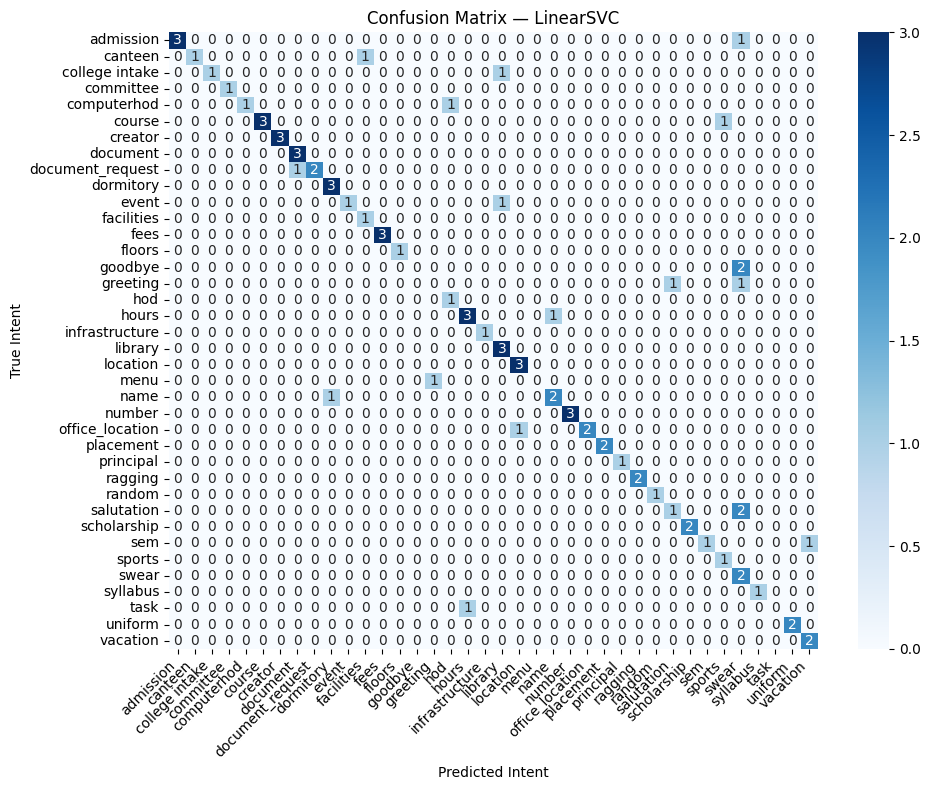

In [13]:
labels = sorted(df['intent'].unique())
cm = confusion_matrix(y_test, best_preds, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted Intent')
plt.ylabel('True Intent')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:
# Error analysis: inspect the misclassified test queries
results_df = pd.DataFrame({
    'query': X_test.values,
    'true_intent': y_test.values,
    'predicted_intent': best_preds
})

misclassified = results_df[results_df['true_intent'] != results_df['predicted_intent']]

print(f"Number of misclassified queries: {len(misclassified)} out of {len(results_df)}")
misclassified


Number of misclassified queries: 19 out of 82


,query,true_intent,predicted_intent
0,whats there on menu,menu,greeting
9,how many stundent are taken in each branch,college intake,library
10,information system,course,sports
11,do you have a name,name,dormitory
21,cya,goodbye,swear
25,good day,greeting,salutation
30,enrolling,admission,swear
31,whatsup,greeting,swear
32,when are you guy open,hours,name
40,why i should use you,task,hours


## Exporting the Final Model for Deployment

Everything evaluated above (the 80/20 split, cross-validation, confusion matrix, error analysis) used a model trained on 80% of the data, so 20% could be held back to honestly test it. For actual deployment, the standard practice is: once you trust the architecture (confirmed above via CV), retrain on **all** available data for maximum real-world coverage, then save that exact trained object to a file.

The cell below does exactly that, and saves two files -- `vectorizer.joblib` and `model.joblib` -- which the Flask backend (`backend/app.py`) loads directly, rather than retraining its own separate copy. This closes the gap between "the model we evaluated" and "the model actually running in the live demo": they become the same trained object, not two independently-trained copies of the same recipe.


In [15]:
import joblib

# Train the FINAL model on all available data (not just the 80% training split --
# the held-out 20% already did its job during evaluation above).
final_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
X_full_tfidf = final_vectorizer.fit_transform(df["clean_query"])

min_class_count_full = df["intent"].value_counts().min()
final_safe_cv = max(2, min(3, min_class_count_full))

final_base_svc = LinearSVC(random_state=RANDOM_STATE, max_iter=10000)
final_model = CalibratedClassifierCV(final_base_svc, cv=final_safe_cv)
final_model.fit(X_full_tfidf, df["intent"])

joblib.dump(final_vectorizer, "vectorizer.joblib")
joblib.dump(final_model, "model.joblib")

print(f"Exported vectorizer.joblib (vocabulary size: {len(final_vectorizer.vocabulary_)})")
print(f"Exported model.joblib (classes: {len(final_model.classes_)})")
print("\nCopy both files AND askcampus_dialogue.py into backend/ in your repo -- app.py loads them directly.")


Exported vectorizer.joblib (vocabulary size: 824)
Exported model.joblib (classes: 38)

Copy both files into backend/ in your repo -- app.py loads them directly.


### Using the final exported model from here on

`predict_intent()` looks up `best_model` / `vectorizer` fresh on every call (not frozen at definition time), so reassigning them here makes `chatbot_response()` and `run_cli_chatbot()` -- including if you run the CLI chatbot below, right here in Colab -- use the exact same trained model object that was just exported to `model.joblib` / `vectorizer.joblib` and that powers the live web demo. Before this cell, those functions were still using the 80/20-split evaluation model from earlier in the notebook.


In [16]:
best_model = final_model
vectorizer = final_vectorizer

print("best_model and vectorizer now point to the final exported model.")
print("Try it: run_cli_chatbot() in the next cell uses this exact model.")


best_model and vectorizer now point to the final exported model.
Try it: run_cli_chatbot() in the next cell uses this exact model.


### Notes on error analysis

- Misclassifications above typically occur between semantically related intents (e.g., *fees* vs. *scholarship*, or *hostel* vs. *facilities*), since they share vocabulary like "office," "available," and "apply."
- `intents.json` gives each intent anywhere from 3 to 27 sample patterns (see the `value_counts()` output in Phase 1) — intents on the low end of that range are the ones most likely to be confused with a neighbor.
- The confidence threshold (`CONFIDENCE_THRESHOLD = 0.35`) can be tuned: raising it makes the bot more cautious (more fallbacks, fewer wrong answers); lowering it makes the bot more willing to guess.


## Summary

| Item | Status |
|---|---|
| Intent classes | 38 (loaded directly from `intents.json`) |
| Sample queries | 409 |
| Preprocessing | Tokenization, lowercasing, punctuation removal, lemmatization (NLTK) |
| Feature extraction | TF-IDF, unigrams + bigrams |
| Models compared | LinearSVC (calibrated), Multinomial Naive Bayes |
| Fallback handling | Confidence-threshold based |
| Response source | `responses` field from `intents.json` (single source of truth) |
| Dialogue context | `askcampus_dialogue.py`: per-user state, sticky fees topic, course entity + fuzzy matching, yes/no follow-up |
| Interface | CLI chat loop (`run_cli_chatbot()`) + Flask web app (same dialogue module) |
| Evaluation | Accuracy, Precision, Recall, F1, Confusion Matrix, Error Analysis |

**Next steps (beyond this prototype):** expand thin intents (the ones with only 3–7 sample patterns) with more real, anonymized student queries, add a web/GUI front-end, and connect responses to live data (e.g., actual enrollment deadlines pulled from a database) instead of static templates.


## Demo: sample conversations

This scripted run doesn't wait for typing, so **Run all** never hangs, and its output covers the *sample conversations* deliverable. `handled by` shows whether the ML model or the context layer produced each reply. The second user shows that conversations are kept separate.

In [ ]:
demo_bot = AskCampusBot(best_model, vectorizer, response_bank, threshold=CONFIDENCE_THRESHOLD)

def show(state, msg, who="Student A"):
    r = demo_bot.respond(msg, state)
    print(f"{who}: {msg}")
    print(f"AskCampus: {r['reply']}")
    print(f"   [intent={r['intent']}, confidence={r['confidence']:.2f}, handled by: {r['handled_by']}]\n")

student_a = ConversationState()
for msg in [
    "hi",
    "what courses do you offer",
    "how much are the fees",
    "computer science",               # answer to the bot's question (context)
    "what about IT",
    "compute4r science",              # typo -> fuzzy match
    "where is the library",           # topic change; 'is' is NOT read as a course
    "what are the fees for information system",
    "how do i enroll",
    "no",
]:
    show(student_a, msg)

print("-" * 60)
student_b = ConversationState()     # a second user with their own conversation
show(student_b, "IT", who="Student B")   # B never asked about fees -> not treated as a fee follow-up


### Interactive chat (run this cell by itself for the live demo)

In [ ]:
run_cli_chatbot(show_debug=True)   # show_debug=False hides the intent/confidence line
